Libraries imported successfully!

Dataset Loaded Successfully!
Dataset Shape: (187, 15)


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country/Region          187 non-null    str    
 1   Confirmed               187 non-null    int64  
 2   Deaths                  187 non-null    int64  
 3   Recovered               187 non-null    int64  
 4   Active                  187 non-null    int64  
 5   New cases               187 non-null    int64  
 6   New deaths              187 non-null    int64  
 7   New recovered           187 non-null    int64  
 8   Deaths / 100 Cases      187 non-null    float64
 9   Recovered / 100 Cases   187 non-null    float64
 10  Deaths / 100 Recovered  187 non-null    float64
 11  Confirmed last week     187 non-null    int64  
 12  1 week change           187 non-null    int64  
 13  1 week % increase       187 non-null    float64
 14  WHO Region              187 non

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase
count,1.870000e+02,187.000000,1.870000e+02,1.870000e+02,187.000000,187.000000,187.000000,187.000000,187.000000,187.00,1.870000e+02,187.000000,187.000000
mean,8.813094e+04,3497.518717,5.063148e+04,3.400194e+04,1222.957219,28.957219,933.812834,3.019519,64.820535,inf,7.868248e+04,9448.459893,13.606203
std,3.833187e+05,14100.002482,1.901882e+05,2.133262e+05,5710.374790,120.037173,4197.719635,3.454302,26.287694,NaN,3.382737e+05,47491.127684,24.509838
min,1.000000e+01,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,1.000000e+01,-47.000000,-3.840000
25%,1.114000e+03,18.500000,6.265000e+02,1.415000e+02,4.000000,0.000000,0.000000,0.945000,48.770000,1.45,1.051500e+03,49.000000,2.775000
50%,5.059000e+03,108.000000,2.815000e+03,1.600000e+03,49.000000,1.000000,22.000000,2.150000,71.320000,3.62,5.020000e+03,432.000000,6.890000
75%,4.046050e+04,734.000000,2.260600e+04,9.149000e+03,419.500000,6.000000,221.000000,3.875000,86.885000,6.44,3.708050e+04,3172.000000,16.855000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,56336.000000,1076.000000,33728.000000,28.560000,100.000000,inf,3.834677e+06,455582.000000,226.320000



Data Cleaning Completed!
Selected Features: ['Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths', 'New recovered']
Cleaned Data Shape: (187, 7)

Feature Scaling Completed!
Scaled Data Shape: (187, 7)


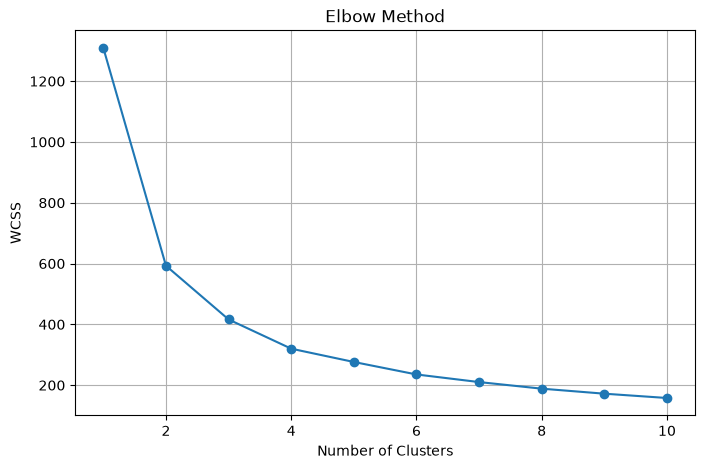


Silhouette Scores:
K=2: 0.4493
K=3: 0.3782
K=4: 0.3461
K=5: 0.3621
K=6: 0.3070
K=7: 0.2995
K=8: 0.3086

Selected Number of Clusters: 2

K-Means Model Trained Successfully!
Final Silhouette Score: 0.4493

Cluster Analysis:


,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered
Cluster,,,,,,,
0,173477.82,6891.86,99406.29,67179.67,2417.22,57.38,1849.94
1,1866.34,66.68,1332.22,467.45,15.85,0.23,7.84


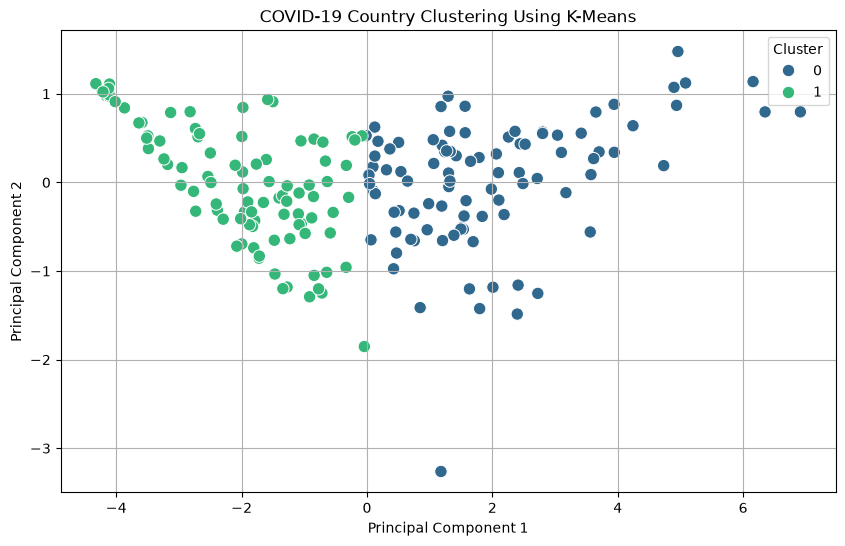

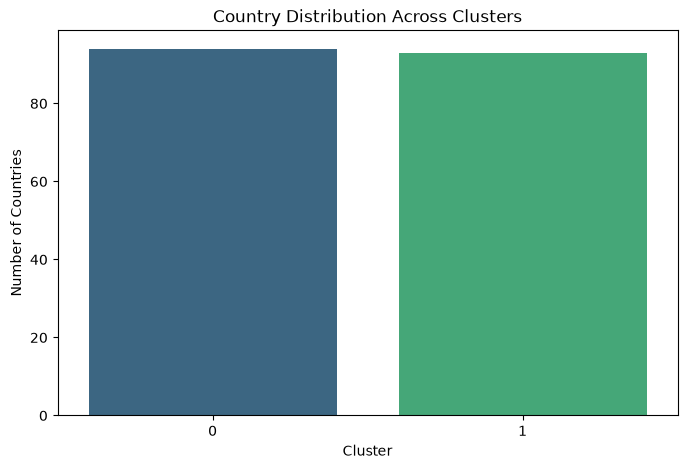


Results exported successfully!

       PROJECT COMPLETED
Algorithm: K-Means Clustering
Dataset: Country Wise COVID-19
Total Countries: 187
Number of Clusters: 2
Silhouette Score: 0.4493

Cluster Distribution:
Cluster
0    94
1    93
Name: count, dtype: int64

Output File: KMeans_COVID_Clustering_Results.csv

PROJECT EXECUTED SUCCESSFULLY!


In [1]:

# ============================================================
# COVID-19 DATA ANALYSIS USING K-MEANS CLUSTERING
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


# 2. LOAD DATASET

df = pd.read_csv("country_wise_latest.csv")

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


# 3. DATA EXPLORATION

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


# 4. DATA CLEANING

df = df.drop_duplicates()

# Identify country column
country_col = next(
    (c for c in ['Country/Region', 'Country'] if c in df.columns),
    None
)

# Select relevant numerical COVID-19 features
features = [
    'Confirmed',
    'Deaths',
    'Recovered',
    'Active',
    'New cases',
    'New deaths',
    'New recovered'
]

features = [c for c in features if c in df.columns]

if len(features) < 2:
    raise ValueError("Not enough numerical features found!")

# Convert selected columns to numeric
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Replace infinite values
data = df[features].replace(
    [np.inf, -np.inf], np.nan
)

# Remove completely empty rows
data = data.dropna(how='all')

# Fill missing values with median
data = data.fillna(data.median())

# Remove constant columns
data = data.loc[:, data.nunique() > 1]

# Keep only non-negative values for log transformation
data = data.clip(lower=0)

print("\nData Cleaning Completed!")
print("Selected Features:", data.columns.tolist())
print("Cleaned Data Shape:", data.shape)


# 5. FEATURE TRANSFORMATION

# Log transformation reduces extreme differences
log_data = np.log1p(data)

# Standardize features
scaler = StandardScaler()

scaled_data = scaler.fit_transform(log_data)

print("\nFeature Scaling Completed!")
print("Scaled Data Shape:", scaled_data.shape)


# 6. ELBOW METHOD

wcss = []

for k in range(1, min(11, len(scaled_data))):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_data)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(wcss) + 1),
    wcss,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()


# 7. SILHOUETTE SCORE

silhouette_scores = {}

max_k = min(8, len(scaled_data) - 1)

for k in range(2, max_k + 1):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_data)

    score = silhouette_score(
        scaled_data,
        labels
    )

    silhouette_scores[k] = score

print("\nSilhouette Scores:")

for k, score in silhouette_scores.items():
    print(f"K={k}: {score:.4f}")

optimal_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print("\nSelected Number of Clusters:", optimal_k)


# 8. TRAIN K-MEANS MODEL

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(scaled_data)

df = df.loc[data.index].copy()

df['Cluster'] = clusters

print("\nK-Means Model Trained Successfully!")

print(
    "Final Silhouette Score:",
    round(silhouette_scores[optimal_k], 4)
)


# 9. CLUSTER ANALYSIS

cluster_summary = df.groupby('Cluster')[features].mean().round(2)

print("\nCluster Analysis:")
display(cluster_summary)


# 10. PCA VISUALIZATION

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame({
    'PCA1': pca_data[:, 0],
    'PCA2': pca_data[:, 1],
    'Cluster': clusters
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='viridis',
    s=80
)

plt.title("COVID-19 Country Clustering Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()


# 11. CLUSTER DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    x=clusters,
    hue=clusters,
    palette='viridis',
    legend=False
)

plt.title("Country Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Countries")
plt.show()


# 12. SAVE RESULTS

output = df.copy()

output.to_csv(
    "KMeans_COVID_Clustering_Results.csv",
    index=False
)

print("\nResults exported successfully!")


# 13. FINAL PROJECT SUMMARY

print("\n====================================")
print("       PROJECT COMPLETED")
print("====================================")

print("Algorithm: K-Means Clustering")
print("Dataset: Country Wise COVID-19")
print("Total Countries:", len(df))
print("Number of Clusters:", optimal_k)

print(
    "Silhouette Score:",
    round(silhouette_scores[optimal_k], 4)
)

print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

print("\nOutput File: KMeans_COVID_Clustering_Results.csv")

print("\nPROJECT EXECUTED SUCCESSFULLY!")
